This script is used to examine the question from Gabrile, how much die significance values is different form the distance we are calculating. 

Here I am using a fixed neighborhood size that is saved in the yaml files and agreed with Sebastian in most of the cases.  

In [26]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import yaml
import seaborn as sns
import numpy as np
import pandas as pd
import scanpy as sc
from scipy import stats
import torch
from scipy import stats
from tqdm import tqdm
from sklearn.metrics import mean_squared_error
import velotest
from velotest.hypothesis_testing import run_hypothesis_test_on
from velotest.neighbors import find_neighbors_in_direction_of_velocity, find_neighbors
import dataframe_image as dfi

In [2]:
def calculateBound(adata, k=None, neighbors=True, number_neighbors=200): 
    if neighbors is True:
        nn_indices_optimal = find_neighbors(torch.tensor(adata.layers['Ms']), k_neighbors=number_neighbors)

    mins = torch.tensor([-2.]*len(adata))
    maxs = torch.tensor([-2.]*len(adata))
    for i in tqdm(range(len(adata))):
        cos = torch.nn.CosineSimilarity(dim=1, eps=1e-6)
        if neighbors is True:
            expression_all = torch.tensor(adata.layers['Ms'][nn_indices_optimal[i]][:,adata.var.velocity_genes])
        else:
            expression_all = torch.tensor(adata.layers['Ms'][:,adata.var.velocity_genes])
        expression_cell = torch.tensor(adata.layers['Ms'][i,adata.var.velocity_genes]).unsqueeze(0)
        velocity = torch.tensor(adata.layers['velocity'][i,adata.var.velocity_genes]).unsqueeze(0)
        cosines = cos(expression_all - expression_cell, velocity)
        cosines = torch.cat([cosines[:i], cosines[i+1:]])
        if k is None:
            mins[i] = torch.min(cosines)
            maxs[i] = torch.max(cosines)
        else:
            mins[i] = torch.mean(torch.topk(cosines, largest=False, k=k).values)
            maxs[i] = torch.mean(torch.topk(cosines, largest=True, k=k).values)

    return maxs

def bestVelocityEmbedded(adata, basis, num=200):
    # Run test - tsne
    uncorrected_p_values, h0_rejected, debug_dict = run_hypothesis_test_on(adata, basis=basis, number_neighbors_to_sample_from=num, null_distribution="velocities-explicit", cosine_empty_neighborhood=None, correction="bonferroni", restrict_to_velocity_genes=True, exclusion_degree=10, n_workers=3)
    statistics = debug_dict['statistics']

    # Calculate emmbeding test optimal statistic
    best_value = [statistics.get_max_value(offset=True)[1] for statistics in statistics if statistics is not None]

    return best_value

For this computation the hindbrain-mouse dataset does not work, because it ends up with a differnt length between best_value and non_empty neighborshoods...

In [8]:
datasets = {
        "Pancreas_dynamical": "/mnt/volume/Johanna_Velotest/configs/pancreas_dynamic.yaml",
        "Pancreas_stochastic": "/mnt/volume/Johanna_Velotest/configs/pancreas_stochastic.yaml",
        "Dentate_gyrus": "/mnt/volume/Johanna_Velotest/configs/dentategyrus.yaml",
        "Gastrulation_erythroid": "/mnt/volume/Johanna_Velotest/configs/gastrulation.yaml",
        "Bone_marrow": "/mnt/volume/Johanna_Velotest/configs/bonemarrow.yaml",
        "PBMC": "/mnt/volume/Johanna_Velotest/configs/pbmc.yaml",
        "Covid": "/mnt/volume/Johanna_Velotest/configs/covid.yaml",
        "Retinal_development": "/mnt/volume/Johanna_Velotest/configs/retinal_development.yaml",
        "Human_HSC": "/mnt/volume/Johanna_Velotest/configs/humanHSC.yaml",
        "Intestinal_development": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/intestinal_organoids.yaml",
        "Hindbrain_mouse": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/hindbrain.yaml",
        "Oligodendrocyte_mouse": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/oligodendrocyte.yaml",
        "Bone_marrow_mouse": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/mouse_bonemarrow.yaml",
        "Cerebral_cortex_human": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/human_cerebral.yaml",
        "Hematopoiesis_mouse": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/mouse_hema.yaml",
        "Spermatogenisis": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/spermatogenesis.yaml",
        "Old_brain": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/old_brain.yaml",
        "Prefrontal_cortex": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/pfc.yaml",
        "Intestinal_organoids":"/mnt/volume/Johanna_Velotest/configs/noEmbedding/GSE128365.yaml"
    }

In [7]:
results = {}

for name, path in datasets.items():
    # Calculte PCA and original values
    with open(path, "r") as f:
            config = yaml.safe_load(f)

    adata = sc.read(config['path'])
    neighbors = config['number_neighbors_to_sample_from']
    basis = config['basis']
    

    upper_bound = adata.obsm['upper_max_neighbors']
    print("Upper bound done")
    uncorrected_p_values, h0_rejected, debug_dict = run_hypothesis_test_on(adata, 
                                                                           basis=basis,
                                                                           number_neighbors_to_sample_from=neighbors, 
                                                                           null_distribution="velocities-explicit", 
                                                                           cosine_empty_neighborhood=None, 
                                                                           correction="bonferroni", 
                                                                           restrict_to_velocity_genes=True, 
                                                                           exclusion_degree=10)
    # Calculate Test optimal bound
    print("Velotest done")
    statistics = debug_dict['statistics']
    non_empty_neighborhoods_indices = np.where(uncorrected_p_values != 2)[0]
    print(len(non_empty_neighborhoods_indices))
    best_value = [statistics.get_max_value(offset=True)[1] for statistics in statistics if statistics is not None]
    print(len(best_value))
    # Get distance value(y)
    distance = stats.wasserstein_distance(upper_bound, best_value)
    #mse = mean_squared_error(upper_bound[non_empty_neighborhoods_indices], best_value)

    # Get significance value(x)
    significance = np.sum(h0_rejected) / len(adata) * 100

    results[name] = {
        'significance': significance,
        'wasserstein': distance,
        #'mse': mse
    }

df = pd.DataFrame(results)
df.to_csv("/mnt/volume/Johanna_Velotest/results/distances/comparison_sig_was_mse_fixedN5.csv")

Upper bound done
Dropping all the genes which are not velocity genes. 283 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 13501/13501 [01:40<00:00, 134.33it/s]


Velotest done
13263
13269


In [17]:
df1 = pd.read_csv("/mnt/volume/Johanna_Velotest/results/distances/comparison_sig_was_mse_fixedN.csv", index_col=0)
df2 = pd.read_csv("/mnt/volume/Johanna_Velotest/results/distances/comparison_sig_was_mse_fixedN2.csv", index_col=0)
df3 = pd.read_csv("/mnt/volume/Johanna_Velotest/results/distances/comparison_sig_was_mse_fixedN3.csv", index_col=0)
df4 = pd.read_csv("/mnt/volume/Johanna_Velotest/results/distances/comparison_sig_was_mse_fixedN4.csv", index_col=0)
df5 = pd.read_csv("/mnt/volume/Johanna_Velotest/results/distances/comparison_sig_was_mse_fixedN5.csv", index_col=0)
df = pd.concat([df1, df2, df3, df4, df5], axis=1)
df

,Pancreas_dynamical,Pancreas_stochastic,Dentate_gyrus,Gastrulation_erythroid,Bone_marrow,PBMC,Covid,Retinal_development,Bone_marrow_mouse,Cerebral_cortex_human,Hematopoiesis_mouse,Spermatogenisis,Old_brain,Prefrontal_cortex,Intestinal_organoids,Oligodendrocyte_mouse,Human_HSC,Intestinal_development,Hindbrain_mouse
significance,8.225108,9.496753,5.972696,4.024452,2.283737,2.609408,2.048114,5.832722,7.653846,5.028766,3.724605,5.030071,4.827208,5.919495,2.766902,5.380955,5.532098,4.075987,3.088660
wasserstein,0.179000,0.064260,0.084482,0.196480,0.304350,0.783949,0.195718,0.175963,0.153135,0.155007,0.056665,0.048025,0.140553,0.206573,0.154240,0.490552,0.362253,0.191864,0.341853
mse,0.044885,0.006670,0.009667,0.043886,0.190624,0.761954,0.062277,0.048882,0.043004,0.030720,0.004927,0.004678,0.057980,0.135227,0.038992,0.474795,0.154392,0.043872,NaN


In [18]:
more_info = {}
for name, path in datasets.items():
    with open(path, "r") as f:
            config = yaml.safe_load(f)

    adata = sc.read(config['path'])
    general = adata.obsm['general_bound']
    upper = adata.obsm['upper_max_neighbors']
    more_info[name] = {
        'cellcount': adata.n_obs,
        'median_general': np.median(general),
        'median_upper': np.median(upper)
    }
more_df = pd.DataFrame(more_info)
df = pd.concat([df, more_df])
df


,Pancreas_dynamical,Pancreas_stochastic,Dentate_gyrus,Gastrulation_erythroid,Bone_marrow,PBMC,Covid,Retinal_development,Bone_marrow_mouse,Cerebral_cortex_human,Hematopoiesis_mouse,Spermatogenisis,Old_brain,Prefrontal_cortex,Intestinal_organoids,Oligodendrocyte_mouse,Human_HSC,Intestinal_development,Hindbrain_mouse
significance,8.225108,9.496753,5.972696,4.024452,2.283737,2.609408,2.048114,5.832722,7.653846,5.028766,3.724605,5.030071,4.827208,5.919495,2.766902,5.380955,5.532098,4.075987,3.088660
wasserstein,0.179000,0.064260,0.084482,0.196480,0.304350,0.783949,0.195718,0.175963,0.153135,0.155007,0.056665,0.048025,0.140553,0.206573,0.154240,0.490552,0.362253,0.191864,0.341853
mse,0.044885,0.006670,0.009667,0.043886,0.190624,0.761954,0.062277,0.048882,0.043004,0.030720,0.004927,0.004678,0.057980,0.135227,0.038992,0.474795,0.154392,0.043872,NaN
cellcount,3696.000000,3696.000000,2930.000000,9815.000000,5780.000000,65877.000000,3076.000000,2726.000000,2600.000000,4693.000000,1772.000000,1829.000000,1823.000000,1267.000000,3831.000000,36146.000000,11605.000000,5422.000000,13501.000000
median_general,0.631016,0.188627,0.262898,0.325245,0.864384,0.988181,0.411061,0.596886,0.502733,0.357680,0.285086,0.157690,0.543127,0.950767,0.589433,0.977665,0.596633,0.396346,0.665440
median_upper,0.478582,0.178481,0.230341,0.252077,0.768736,0.968400,0.348440,0.452733,0.357217,0.326670,0.181990,0.131328,0.406782,0.919779,0.274573,0.965415,0.538582,0.344104,0.537528


In [61]:
all = pd.concat([df, x], axis =0)
all.to_csv("/mnt/volume/Johanna_Velotest/results/distances/comparison_sig_was_mse_ALL.csv")

In [19]:
df.T

,significance,wasserstein,mse,cellcount,median_general,median_upper
Pancreas_dynamical,8.225108,0.179000,0.044885,3696.0,0.631016,0.478582
Pancreas_stochastic,9.496753,0.064260,0.006670,3696.0,0.188627,0.178481
Dentate_gyrus,5.972696,0.084482,0.009667,2930.0,0.262898,0.230341
Gastrulation_erythroid,4.024452,0.196480,0.043886,9815.0,0.325245,0.252077
Bone_marrow,2.283737,0.304350,0.190624,5780.0,0.864384,0.768736
PBMC,2.609408,0.783949,0.761954,65877.0,0.988181,0.968400
Covid,2.048114,0.195718,0.062277,3076.0,0.411061,0.348440
Retinal_development,5.832722,0.175963,0.048882,2726.0,0.596886,0.452733
Bone_marrow_mouse,7.653846,0.153135,0.043004,2600.0,0.502733,0.357217
Cerebral_cortex_human,5.028766,0.155007,0.030720,4693.0,0.357680,0.326670


In [28]:
styled_df = (df.T.style
             .format(precision=0) # Rounds display to 3 decimal places
             .format({"cellcount": "{:.0f}"}) # Keeps cellcount as an integer
             .background_gradient(cmap='coolwarm', axis=0) # Color codes per column
             .highlight_null(color='gray'))
styled_df

,significance,wasserstein,mse,cellcount,median_general,median_upper
Pancreas_dynamical,8.225108,0.179000,0.044885,3696,0.631016,0.478582
Pancreas_stochastic,9.496753,0.064260,0.006670,3696,0.188627,0.178481
Dentate_gyrus,5.972696,0.084482,0.009667,2930,0.262898,0.230341
Gastrulation_erythroid,4.024452,0.196480,0.043886,9815,0.325245,0.252077
Bone_marrow,2.283737,0.304350,0.190624,5780,0.864384,0.768736
PBMC,2.609408,0.783949,0.761954,65877,0.988181,0.968400
Covid,2.048114,0.195718,0.062277,3076,0.411061,0.348440
Retinal_development,5.832722,0.175963,0.048882,2726,0.596886,0.452733
Bone_marrow_mouse,7.653846,0.153135,0.043004,2600,0.502733,0.357217
Cerebral_cortex_human,5.028766,0.155007,0.030720,4693,0.357680,0.326670


                       significance wasserstein       mse cellcount
Pancreas_dynamical         8.225108       0.179  0.044885      3696
Pancreas_stochastic        9.496753     0.06426   0.00667      3696
Dentate_gyrus              5.972696    0.084482  0.009667      2930
Gastrulation_erythroid     4.024452     0.19648  0.043886      9815
Bone_marrow                2.283737     0.30435  0.190624      5780
PBMC                       2.609408    0.783949  0.761954     65877
Covid                      2.048114    0.195718  0.062277      3076
Retinal_development        5.832722    0.175963  0.048882      2726
Bone_marrow_mouse          7.653846    0.153135  0.043004      2600
Cerebral_cortex_human      5.028766    0.155007   0.03072      4693
Hematopoiesis_mouse        3.724605    0.056665  0.004927      1772
Spermatogenisis            5.030071    0.048025  0.004678      1829
Old_brain                  4.827208    0.140553   0.05798      1823
Prefrontal_cortex          5.919495    0.206573 

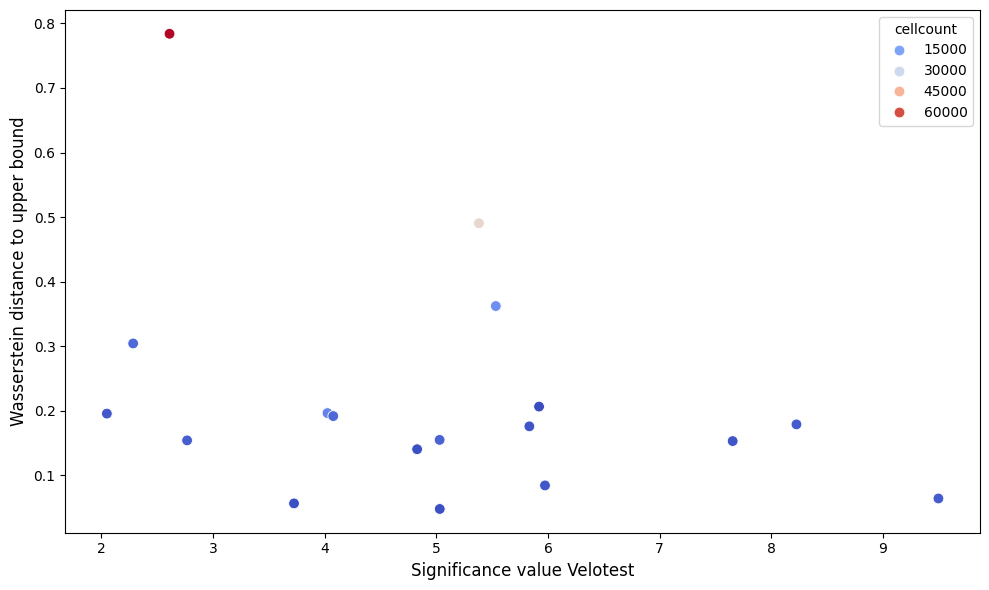

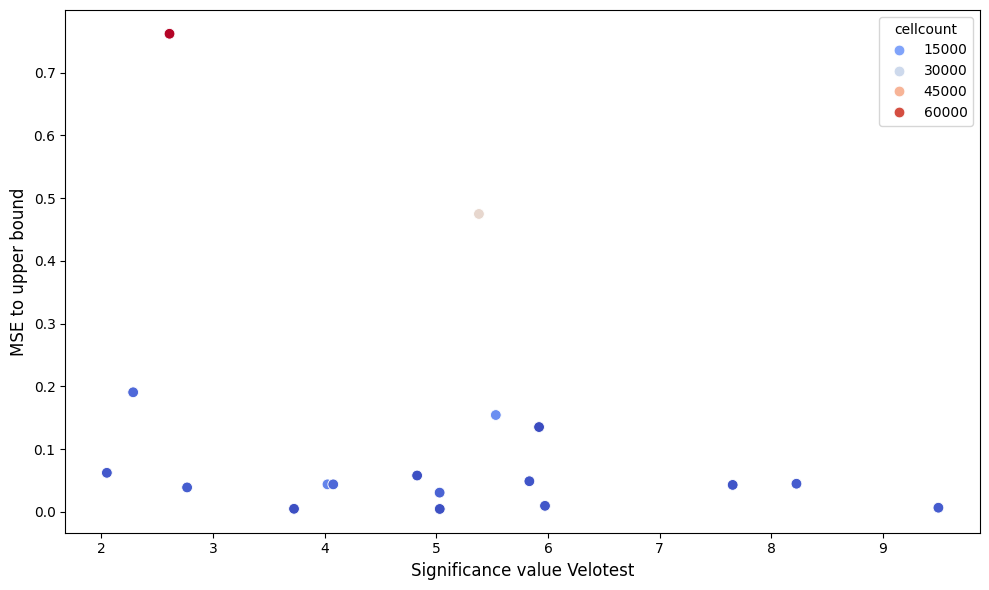

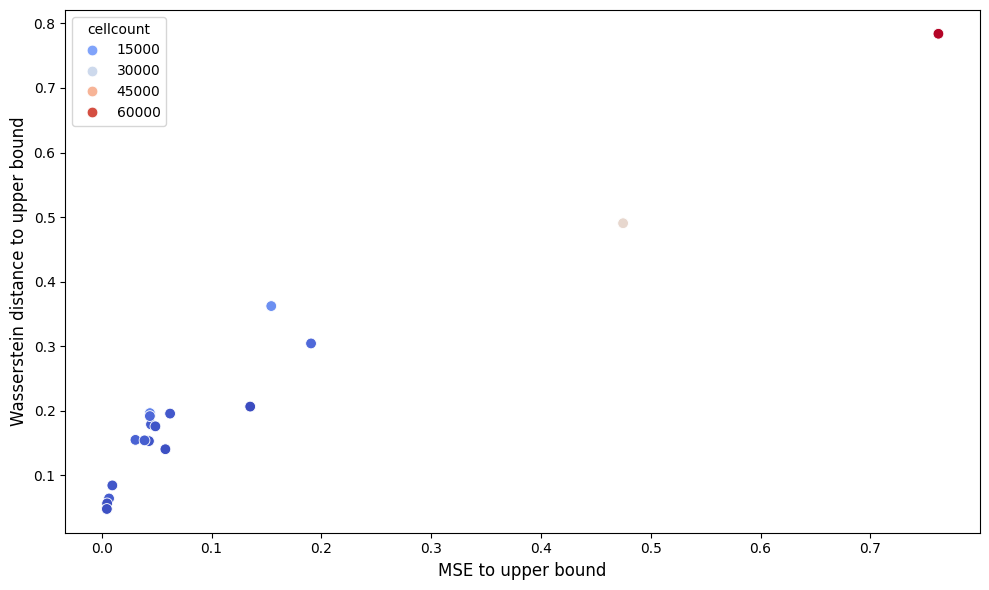

In [ ]:
# Plot data
plot_df = all.T
print(plot_df)

plt.figure(figsize=(10, 6))

sns.scatterplot(data=plot_df, x= 'significance', y='wasserstein', hue='cellcount', 
    palette='coolwarm',s=60)
plt.xlabel('Significance value Velotest', fontsize=12)
plt.ylabel('Wasserstein distance to upper bound', fontsize=12)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))

sns.scatterplot(data=plot_df, x= 'significance', y='mse', hue='cellcount', 
    palette='coolwarm',s=60)
plt.xlabel('Significance value Velotest', fontsize=12)
plt.ylabel('MSE to upper bound', fontsize=12)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))

sns.scatterplot(data=plot_df, x= 'mse', y='wasserstein', hue='cellcount', 
    palette='coolwarm',s=60)
plt.xlabel('MSE to upper bound', fontsize=12)
plt.ylabel('Wasserstein distance to upper bound', fontsize=12)
plt.tight_layout()
plt.show()